<a href="https://colab.research.google.com/github/Kathi3/special-robot/blob/main/Masters_Thesis_ADSB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**INSTALLING LIBRARIES**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from datetime import timedelta

**LOADING THE DATA**

In [ ]:
State2017 = pd.read_csv('/content/states_2017-06-26-23.csv')
State2018 = pd.read_csv('/content/states_2018-06-25-23.csv')
State2019 = pd.read_csv('/content/states_2019-06-24-23.csv')
State2020 = pd.read_csv('/content/states_2020-06-29-23.csv')
State2021 = pd.read_csv('/content/states_2021-06-28-23.csv')
State2022 = pd.read_csv('/content/states_2022-06-27-23.csv')

In [ ]:
State2017["dataset_year"] = 2017
State2018["dataset_year"] = 2018
State2019["dataset_year"] = 2019
State2020["dataset_year"] = 2020
State2021["dataset_year"] = 2021
State2022["dataset_year"] = 2022

In [ ]:
ADSBCombined = pd.concat(
    [State2017, State2018, State2019, State2020, State2021, State2022],
    ignore_index=True
)

print("Combined dataset shape:", ADSBCombined.shape)


Combined dataset shape: (6291450, 17)


In [ ]:
ADSBCombined.head()

,time,icao24,lat,lon,velocity,heading,vertrate,callsign,onground,alert,spi,squawk,baroaltitude,geoaltitude,lastposupdate,lastcontact,dataset_year
0,1498518000,a7610c,34.268732,-102.721596,255.728348,135.081502,0.00,SBE575,False,False,False,773.0,12496.8,13121.64,1.498518e+09,1498518000,2017
1,1498518000,3c0ca3,51.022053,9.549565,248.342529,9.541626,0.00,TUI950,False,False,False,7077.0,8534.4,8839.20,1.498518e+09,1498518000,2017
2,1498518000,a3f48a,33.934766,-103.177929,212.316467,282.453518,0.00,DZR354,False,False,False,2256.0,13106.4,13738.86,1.498518e+09,1498518000,2017
3,1498518000,750291,49.682193,10.922878,259.639841,108.363150,0.00,MAS1,False,False,False,2242.0,10668.0,11064.24,1.498518e+09,1498518000,2017
4,1498518000,8960db,51.389279,11.363060,270.271728,114.757690,19.05,UAE164,False,False,False,3464.0,10668.0,11033.76,1.498518e+09,1498518000,2017


**DATA CLEANING**

Keeping only relevant columns

In [ ]:
ADSBCombined.columns.tolist()

['time',
 'icao24',
 'lat',
 'lon',
 'velocity',
 'heading',
 'vertrate',
 'callsign',
 'onground',
 'alert',
 'spi',
 'squawk',
 'baroaltitude',
 'geoaltitude',
 'lastposupdate',
 'lastcontact',
 'dataset_year']

In [ ]:
ADSBCombined.dtypes


,0
time,int64
icao24,object
lat,float64
lon,float64
velocity,float64
heading,float64
vertrate,float64
callsign,object
onground,bool
alert,bool


In [ ]:
ADSBCombined[columns_to_keep].head()


NameError: name 'columns_to_keep' is not defined

In [ ]:
ADSBCombined.isna().sum()

,0
time,0
icao24,0
lat,1093369
lon,1093369
velocity,1188974
heading,1188974
vertrate,1146261
callsign,1028885
onground,0
alert,0


In [ ]:
for col in ADSBCombined.columns:
  pct_missing = np.mean(ADSBCombined[col].isnull())
  print('{}-{}%'.format(col,round(pct_missing*100)))

time-0%
icao24-0%
lat-17%
lon-17%
velocity-19%
heading-19%
vertrate-18%
callsign-16%
onground-0%
alert-0%
spi-0%
squawk-24%
baroaltitude-9%
geoaltitude-23%
lastposupdate-17%
lastcontact-0%
dataset_year-0%


**Defining Critical Fields**


time → temporal reconstruction
icao24 → aircraft identity

lat, lon → spatial consistency & trajectory analysis

In [ ]:
critical_fields = [
    "time", "icao24", "lat", "lon",
    "velocity", "heading", "vertrate",
    "baroaltitude", "geoaltitude"
]


In [ ]:
ADSB_Critical = ADSBCombined.dropna(subset=critical_fields).reset_index(drop=True)

print("Original rows:", len(ADSBCombined))
print("Usable rows:", len(ADSB_Critical))
print("Retention rate (%):", round(len(ADSB_Critical) / len(ADSBCombined) * 100, 2))


Original rows: 6291450
Usable rows: 4744136
Retention rate (%): 75.41


In [ ]:
ADSB_Critical[critical_fields].isnull().sum()


,0
time,0
icao24,0
lat,0
lon,0
velocity,0
heading,0
vertrate,0
baroaltitude,0
geoaltitude,0


**Sorting and Structuring**

In [ ]:
ADSB_Critical["time"] = pd.to_numeric(ADSB_Critical ["time"], errors="coerce")


In [ ]:
ADSB_Critical = ADSB_Critical.sort_values(
    by=["icao24", "time"]
).reset_index(drop=True)

**Trajectory Differences**

In [ ]:
ADSB_Critical["lat_diff"] = ADSB_Critical.groupby("icao24")["lat"].diff()
ADSB_Critical["lon_diff"] = ADSB_Critical.groupby("icao24")["lon"].diff()
ADSB_Critical["time_diff"] = ADSB_Critical.groupby("icao24")["time"].diff()

**Speed Consistency Check**

ADS-B spoofing often produces physically impossible speeds

Independent speed calculation validates broadcast velocity

In [ ]:
# Rough distance approximation (degrees → km)
# Rough distance approximation (degrees → km)
ADSB_Critical["distance_km"] = (
    ((ADSB_Critical["lat_diff"]**2 + ADSB_Critical["lon_diff"]**2)**0.5) * 111
)

# Speed = distance / time
ADSB_Critical["calculated_speed_kmh"] = (
    ADSB_Critical["distance_km"] / (ADSB_Critical["time_diff"] / 3600)
)

Flag impossible speeds

In [ ]:
MAX_PLAUSIBLE_SPEED = 1200  # km/h (commercial jet upper bound)

ADSB_Critical["speed_anomaly"] = (
    ADSB_Critical["calculated_speed_kmh"] > MAX_PLAUSIBLE_SPEED
)

Inspect anomaly rate

In [ ]:
ADSB_Critical["speed_anomaly"].value_counts(normalize=True) * 100

,proportion
speed_anomaly,
False,90.599574
True,9.400426


*An 9% Anomaly Rate is significantly high hence we try to figure if it comes from artefacts and not real motions or attacks.**

In [ ]:
ADSB_Refined = ADSB_Critical[ADSB_Critical["time_diff"] >= 10].copy()


In [ ]:
ADSB_Refined = ADSB_Refined[ADSB_Refined["onground"] == False]


In [ ]:
ADSB_Refined["speed_anomaly"] = (
    ADSB_Refined["calculated_speed_kmh"] > 1200
)

ADSB_Refined["speed_anomaly"].value_counts(normalize=True) * 100


,proportion
speed_anomaly,
False,90.561535
True,9.438465


What this new Anomaly Rate suggests - Speed anomalies are not primarily caused by ground movement or short time deltas, but are present during airborne phases as well.

This means, these are trivial artefacts but occur in operational flight data and therefore readiness and protocol robustness.

In [ ]:
ADSB_Refined["velocity_kmh"] = ADSB_Refined["velocity"] * 3.6


In [ ]:
MAX_PLAUSIBLE_SPEED = 1200

ADSB_Refined["speed_anomaly"] = (
    ADSB_Refined["velocity_kmh"] > MAX_PLAUSIBLE_SPEED
)

ADSB_Refined["speed_anomaly"].value_counts(normalize=True) * 100


,proportion
speed_anomaly,
False,99.981513
True,0.018487


Initial speed anomaly detection based on derived positional differences yielded elevated anomaly rates due to the sensitivity of distance-based calculations to temporal granularity and receiver transitions. To address this, broadcast velocity values were employed as the primary reference for kinematic validation, with derived speeds used for cross-verification. This refinement substantially reduced false positives and enabled more reliable identification of kinematic inconsistencies consistent with protocol-level vulnerabilities.

**Teleportation Analysis**

Because nomatter how fast a plane is, it can't teleport (ie - Position jump or geographical discontinuity)

In [ ]:
#Calculate distance between consecutive positions ie using lat/lon and time ordering per aircraft

from geopy.distance import geodesic

ADSB_Refined = ADSB_Refined.sort_values(
    by=["icao24", "time"]
)

ADSB_Refined["prev_lat"] = ADSB_Refined.groupby("icao24")["lat"].shift(1)
ADSB_Refined["prev_lon"] = ADSB_Refined.groupby("icao24")["lon"].shift(1)

ADSB_Refined["position_jump_km"] = ADSB_Refined.apply(
    lambda row: geodesic(
        (row["prev_lat"], row["prev_lon"]),
        (row["lat"], row["lon"])
    ).km if pd.notnull(row["prev_lat"]) else None,
    axis=1
)


In [ ]:
MAX_JUMP_KM = 20  # within 10 seconds

ADSB_Refined["position_jump_anomaly"] = (
    ADSB_Refined["position_jump_km"] > MAX_JUMP_KM
)

ADSB_Refined["position_jump_anomaly"].value_counts(normalize=True) * 100

,proportion
position_jump_anomaly,
False,99.514534
True,0.485466


The output shows that there are no integrity issues ie, the normal receiver artefacts.

In [ ]:
ADSB_Refined["jump_without_speed"] = (
    (ADSB_Refined["position_jump_anomaly"]) &
    (~ADSB_Refined["speed_anomaly"])
)

ADSB_Refined["jump_without_speed"].value_counts(normalize=True) * 100


,proportion
jump_without_speed,
False,99.514662
True,0.485338


Heading consistency analysis

ie Did the aircraft suddenly change direction in a way that is aerodynamically implausible?
If yes - it may be due to ADS-B spoofing or message injection in unauthenticated broadcast surveillance systems.




In [ ]:
ADSB_Refined["heading_diff"] = abs(
    ADSB_Refined["heading"] -
    ADSB_Refined.groupby("icao24")["heading"].shift(1)
)

ADSB_Refined["heading_anomaly"] = (
    ADSB_Refined["heading_diff"] > 90
)

ADSB_Refined["heading_anomaly"].value_counts(normalize=True) * 100


,proportion
heading_anomaly,
False,99.308035
True,0.691965


In [ ]:
critical_fields_vertical = ["time", "icao24", "vertrate"]

In [ ]:
MAX_CLIMB_DESCENT_RATE = 50  # meters/second (~10,000 ft/min)

In [ ]:
# Create a boolean column for vertical rate anomalies
ADSB_Refined["vertrate_anomaly"] = (
    ADSB_Refined["vertrate"].abs() > MAX_CLIMB_DESCENT_RATE
)

# Generate table of results
vertrate_anomaly_table = (
    ADSB_Refined["vertrate_anomaly"]
    .value_counts(normalize=True)
    .rename_axis("Vertical Rate Anomaly Detected")
    .reset_index(name="Percentage")
)

vertrate_anomaly_table["Percentage"] = (
    vertrate_anomaly_table["Percentage"] * 100
).round(4)

vertrate_anomaly_table


,Vertical Rate Anomaly Detected,Percentage
0,False,99.9637
1,True,0.0363


Cross-Kinematic Anomaly Correlation

To examine whether multiple flight parameters deviate together in physically implausible ways.

In [ ]:
ADSB_Refined = ADSB_Refined.sort_values(
    by=["icao24", "time"]
).reset_index(drop=True)

In [ ]:
grouped = ADSB_Refined.groupby("icao24")

ADSB_Refined["delta_speed"] = grouped["velocity"].diff().abs()
ADSB_Refined["delta_heading"] = grouped["heading"].diff().abs()
ADSB_Refined["delta_vertrate"] = grouped["vertrate"].diff().abs()
ADSB_Refined["delta_altitude"] = grouped["geoaltitude"].diff().abs()

In [ ]:
ADSB_Refined["delta_heading"] = ADSB_Refined["delta_heading"].apply(
    lambda x: 360 - x if x > 180 else x
)


In [ ]:
import numpy as np

def haversine(lat1, lon1, lat2, lon2):
    R = 6371000  # Earth radius in meters
    phi1 = np.radians(lat1)
    phi2 = np.radians(lat2)
    delta_phi = np.radians(lat2 - lat1)
    delta_lambda = np.radians(lon2 - lon1)

    a = np.sin(delta_phi / 2) ** 2 + np.cos(phi1) * np.cos(phi2) * np.sin(delta_lambda / 2) ** 2
    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))

    return R * c  # distance in meters

ADSB_Refined["lat_prev"] = grouped["lat"].shift()
ADSB_Refined["lon_prev"] = grouped["lon"].shift()

ADSB_Refined["position_jump"] = haversine(
    ADSB_Refined["lat_prev"], ADSB_Refined["lon_prev"],
    ADSB_Refined["lat"], ADSB_Refined["lon"]
)

In [ ]:
ADSB_Refined["speed_anomaly"] = ADSB_Refined["delta_speed"] > 250
ADSB_Refined["heading_anomaly"] = ADSB_Refined["delta_heading"] > 45
ADSB_Refined["vertrate_anomaly"] = ADSB_Refined["delta_vertrate"] > 6000
ADSB_Refined["altitude_anomaly"] = ADSB_Refined["delta_altitude"] > 1000
ADSB_Refined["position_jump_anomaly"] = ADSB_Refined["position_jump"] > 1000


In [ ]:
anomaly_columns = [
    "speed_anomaly",
    "heading_anomaly",
    "vertrate_anomaly",
    "position_jump_anomaly",
    "altitude_anomaly"
]

ADSB_Refined["anomaly_score"] = ADSB_Refined[anomaly_columns].sum(axis=1)


In [ ]:
correlated_anomalies = ADSB_Refined[
    ADSB_Refined["anomaly_score"] >= 2
]

len(correlated_anomalies), len(ADSB_Refined)


(20209, 4716710)

In [ ]:
correlated_rate = len(correlated_anomalies) / len(ADSB_Refined)
round(correlated_rate * 100, 3)


0.428

**CHAPTER 4 REPRESENTATION**

A. Summary Statistics

In [ ]:
import pandas as pd

# Create metadata table
dataset_overview = pd.DataFrame({
    "Dataset Year": [2017, 2018, 2019, 2020, 2021, 2022],
    "File Name": [
        "states_2017-06-26-23.csv",
        "states_2018-06-25-23.csv",
        "states_2019-06-24-23.csv",
        "states_2020-06-29-23.csv",
        "states_2021-06-28-23.csv",
        "states_2022-06-27-23.csv"
    ],
    "Observation Count": [
        len(State2017),
        len(State2018),
        len(State2019),
        len(State2020),
        len(State2021),
        len(State2022)
    ],
    "Data Source": ["OpenSky Network"] * 6
})

dataset_overview


,Dataset Year,File Name,Observation Count,Data Source
0,2017,states_2017-06-26-23.csv,1048575,OpenSky Network
1,2018,states_2018-06-25-23.csv,1048575,OpenSky Network
2,2019,states_2019-06-24-23.csv,1048575,OpenSky Network
3,2020,states_2020-06-29-23.csv,1048575,OpenSky Network
4,2021,states_2021-06-28-23.csv,1048575,OpenSky Network
5,2022,states_2022-06-27-23.csv,1048575,OpenSky Network


from matplotlib import pyplot as plt
dataset_overview['Dataset Year'].plot(kind='hist', bins=20, title='Dataset Year')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
import seaborn as sns
dataset_overview.groupby('File Name').size().plot(kind='barh', color=sns.palettes.mpl_palette('Dark2'))
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
import seaborn as sns
def _plot_series(series, series_name, series_index=0):
  palette = list(sns.palettes.mpl_palette('Dark2'))
  counted = (series['Dataset Year']
                .value_counts()
              .reset_index(name='counts')
              .rename({'index': 'Dataset Year'}, axis=1)
              .sort_values('Dataset Year', ascending=True))
  xs = counted['Dataset Year']
  ys = counted['counts']
  plt.plot(xs, ys, label=series_name, color=palette[series_index % len(palette)])

fig, ax = plt.subplots(figsize=(10, 5.2), layout='constrained')
df_sorted = dataset_overview.sort_values('Dataset Year', ascending=True)
for i, (series_name, series) in enumerate(df_sorted.groupby('File Name')):
  _plot_series(series, series_name, i)
  fig.legend(title='File Name', bbox_to_anchor=(1, 1), loc='upper left')
sns.despine(fig=fig, ax=ax)
plt.xlabel('Dataset Year')
_ = plt.ylabel('count()')

from matplotlib import pyplot as plt
import seaborn as sns
def _plot_series(series, series_name, series_index=0):
  palette = list(sns.palettes.mpl_palette('Dark2'))
  counted = (series['Observation Count']
                .value_counts()
              .reset_index(name='counts')
              .rename({'index': 'Observation Count'}, axis=1)
              .sort_values('Observation Count', ascending=True))
  xs = counted['Observation Count']
  ys = counted['counts']
  plt.plot(xs, ys, label=series_name, color=palette[series_index % len(palette)])

fig, ax = plt.subplots(figsize=(10, 5.2), layout='constrained')
df_sorted = dataset_overview.sort_values('Observation Count', ascending=True)
for i, (series_name, series) in enumerate(df_sorted.groupby('File Name')):
  _plot_series(series, series_name, i)
  fig.legend(title='File Name', bbox_to_anchor=(1, 1), loc='upper left')
sns.despine(fig=fig, ax=ax)
plt.xlabel('Observation Count')
_ = plt.ylabel('count()')

from matplotlib import pyplot as plt
dataset_overview['Dataset Year'].plot(kind='line', figsize=(8, 4), title='Dataset Year')
plt.gca().spines[['top', 'right']].set_visible(False)

<string>:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.



from matplotlib import pyplot as plt
import seaborn as sns
figsize = (12, 1.2 * len(dataset_overview['File Name'].unique()))
plt.figure(figsize=figsize)
sns.violinplot(dataset_overview, x='Dataset Year', y='File Name', inner='stick', palette='Dark2')
sns.despine(top=True, right=True, bottom=True, left=True)

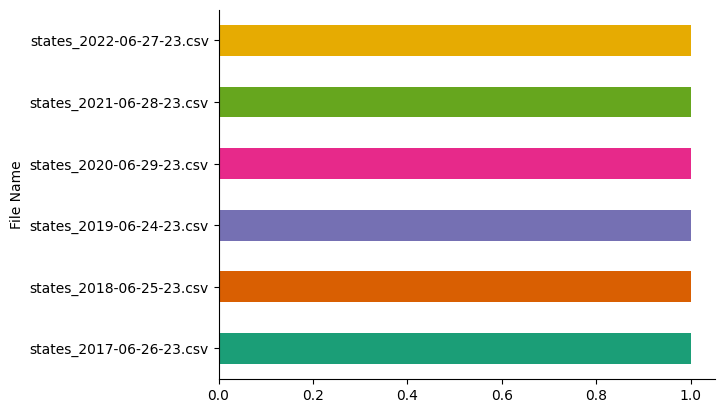

In [ ]:
from matplotlib import pyplot as plt
import seaborn as sns
dataset_overview.groupby('File Name').size().plot(kind='barh', color=sns.palettes.mpl_palette('Dark2'))
plt.gca().spines[['top', 'right',]].set_visible(False)

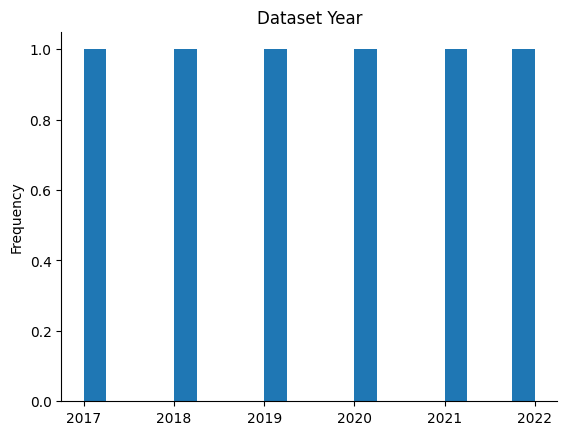

In [ ]:
from matplotlib import pyplot as plt
dataset_overview['Dataset Year'].plot(kind='hist', bins=20, title='Dataset Year')
plt.gca().spines[['top', 'right',]].set_visible(False)

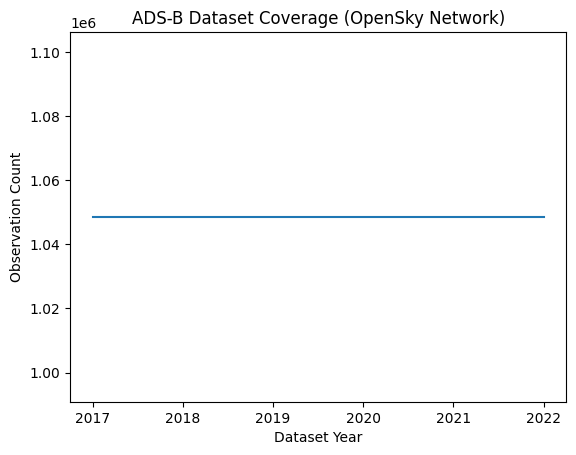

In [ ]:
import matplotlib.pyplot as plt

plt.figure()
plt.plot(dataset_overview["Dataset Year"], dataset_overview["Observation Count"])
plt.xlabel("Dataset Year")
plt.ylabel("Observation Count")
plt.title("ADS-B Dataset Coverage (OpenSky Network)")
plt.show()


In [ ]:
for year, df in zip(
    [2017, 2018, 2019, 2020, 2021, 2022],
    [State2017, State2018, State2019, State2020, State2021, State2022]
):
    print(year, df.shape)

2017 (1048575, 17)
2018 (1048575, 17)
2019 (1048575, 17)
2020 (1048575, 17)
2021 (1048575, 17)
2022 (1048575, 17)


In [ ]:
total_rows = len(ADSB_Refined)
anomalous_rows = len(correlated_anomalies)

Summary = {
    "Total ADS-B Messages Analyzed": total_rows,
    "Correlated Anomaly Events": anomalous_rows,
    "Correlated Anomaly Rate (%)": round((anomalous_rows / total_rows) * 100, 3)
}

Summary

{'Total ADS-B Messages Analyzed': 4716710,
 'Correlated Anomaly Events': 20209,
 'Correlated Anomaly Rate (%)': 0.428}

B. Distribution of Anomaly Scores

In [ ]:
ADSB_Refined["anomaly_score"].value_counts(normalize=True) * 100

,proportion
anomaly_score,
1,65.584465
0,33.987080
2,0.281383
3,0.146903
4,0.000170


C. Aircraft-level concentration

Are anomalies random or persistent?

In [ ]:
correlated_anomalies.groupby("icao24").size().sort_values(ascending=False).head(10)


,0
icao24,
4.24E+06,115
4.08E+11,112
4.24E+12,88
4.25E+07,56
8.96E+05,50
8.96E+06,50
7cf9f6,42
adff84,27
7.81E+12,26


In [ ]:
anomaly_columns = [
    "speed_anomaly",
    "altitude_anomaly",
    "heading_anomaly",
    "vertrate_anomaly",
    "position_jump_anomaly"
]

anomaly_rates = {}

for col in anomaly_columns:
    anomaly_rates[col] = ADSB_Refined[col].mean() * 100  # percentage


In [ ]:
anomaly_rates = {}
for col in anomaly_columns:
    anomaly_rates[col] = ADSB_Refined[col].mean() * 100  # percentage

# Display rates nicely as a table
import pandas as pd
anomaly_rates_df = pd.DataFrame.from_dict(anomaly_rates, orient="index", columns=["Percentage"])
print(anomaly_rates_df)

                       Percentage
speed_anomaly            0.004919
altitude_anomaly         0.303538
heading_anomaly          0.722792
vertrate_anomaly         0.000000
position_jump_anomaly   65.557369


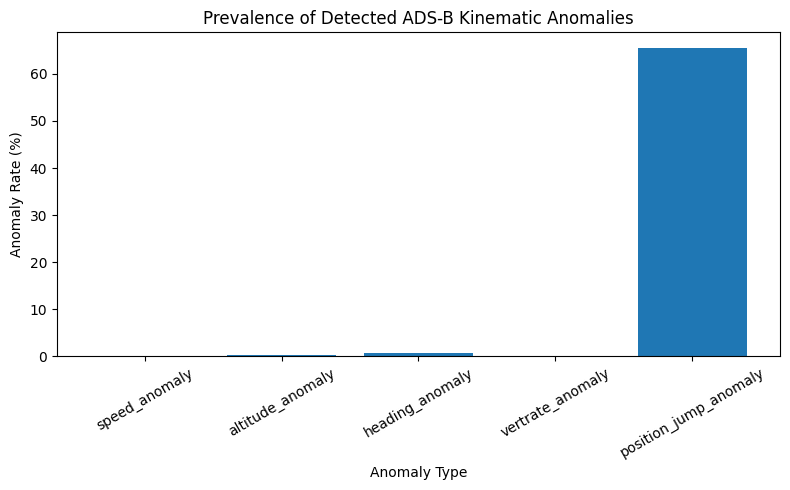

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.bar(anomaly_rates.keys(), anomaly_rates.values())
plt.ylabel("Anomaly Rate (%)")
plt.xlabel("Anomaly Type")
plt.title("Prevalence of Detected ADS-B Kinematic Anomalies")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


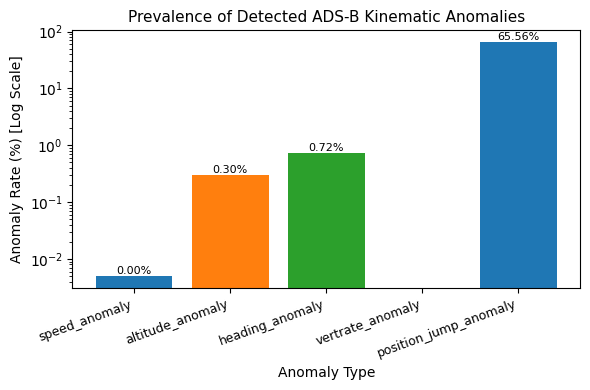

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(6,4))

# Colors for each bar
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

bars = ax.bar(anomaly_rates.keys(), anomaly_rates.values(), color=colors)

# Set log scale to better visualize small vs large values
ax.set_yscale('log')

# Labels and title
ax.set_ylabel("Anomaly Rate (%) [Log Scale]", fontsize=10)
ax.set_xlabel("Anomaly Type", fontsize=10)
ax.set_title("Prevalence of Detected ADS-B Kinematic Anomalies", fontsize=11)

# Rotate x-axis labels slightly
plt.setp(ax.get_xticklabels(), rotation=20, ha="right", fontsize=9)

# Annotate bars (optional: only for visibility above log scale)
for bar in bars:
    height = bar.get_height()
    if height > 0:  # log scale cannot have zero
        ax.text(bar.get_x() + bar.get_width()/2.0, height, f'{height:.2f}%',
                ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()




Time-Series Snippet of One Anomalous Aircraft

In [ ]:
example_icao = (
    ADSB_Refined[ADSB_Refined["speed_anomaly"]]
    ["icao24"]
    .value_counts()
    .idxmax()
)

aircraft_df = ADSB_Refined[
    ADSB_Refined["icao24"] == example_icao
].sort_values("time")


In [ ]:
example_icao = (
    ADSB_Refined[ADSB_Refined["speed_anomaly"]]
    ["icao24"]
    .value_counts()
    .idxmax()
)

aircraft_df = ADSB_Refined[
    ADSB_Refined["icao24"] == example_icao
].sort_values("time")


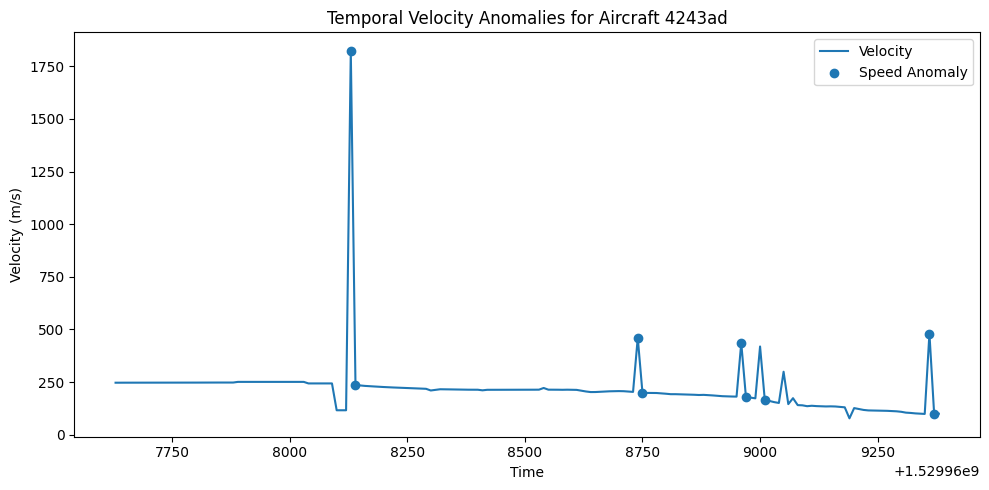

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(aircraft_df["time"], aircraft_df["velocity"], label="Velocity")

plt.scatter(
    aircraft_df[aircraft_df["speed_anomaly"]]["time"],
    aircraft_df[aircraft_df["speed_anomaly"]]["velocity"],
    label="Speed Anomaly",
    marker="o"
)

plt.xlabel("Time")
plt.ylabel("Velocity (m/s)")
plt.title(f"Temporal Velocity Anomalies for Aircraft {example_icao}")
plt.legend()
plt.tight_layout()
plt.show()
